<a href="https://colab.research.google.com/github/moein-13/Computer-Vision-And-Pattern-Recognition/blob/main/Basic_CNN_Implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

Device: cuda
GPU: Tesla T4


In [2]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import seaborn as sns
import os

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

cuda


In [3]:
import zipfile
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Extract the zip file directly into MyDrive
zip_path = '/content/drive/MyDrive/CNN_Assignment.zip'
extract_path = '/content/drive/MyDrive/'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction complete!")

Mounted at /content/drive
Extraction complete!


In [7]:
import zipfile
import os

zip_path = '/content/drive/MyDrive/CNN_Assignment.zip'
extract_path = '/content/drive/MyDrive/'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction complete!")

Extraction complete!


In [8]:
print(os.listdir('/content/drive/MyDrive'))

['Voice 819.m4a', 'Voice 833.m4a', '20240116_093650.heic', 'Engineering Ethics Mid - Presentation', 'received_979092390973843.jpeg', 'received_3972767316375030.jpeg', 'Untitled form.gform', 'Bangladesh Railway e-ticket.pdf', 'Resume.gdoc', '"A Survey on Transportation Challenges Faced by AIUB Students During Monsoon: The Case of Kuratoli Road".gform', 'ML_pics', 'Colab Notebooks', 'Sqlbolt', 'Google AI Studio', 'Flag.gdoc', 'Infix to prefix .gdoc', 'CNN_Assignment.zip', 'CNN_Assignment']


In [9]:
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    if 'blackspotted_orange' in dirs:
        print("Dataset location:", root)

Dataset location: /content/drive/MyDrive/CNN_Assignment/dataset


In [10]:
import os

print(os.listdir('/content/drive/MyDrive/CNN_Assignment'))

['dataset']


In [11]:
dataset_path = '/content/drive/MyDrive/CNN_Assignment/dataset'

import os

print("Dataset exists:", os.path.exists(dataset_path))
print("Classes:", os.listdir(dataset_path))

Dataset exists: True
Classes: ['blackspotted_orange', 'cankered_orange', 'fresh_orange', 'green_orange', 'rotten_orange']


In [12]:
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

In [13]:
full_dataset = datasets.ImageFolder(
    root=dataset_path
)

print("Total images:", len(full_dataset))
print("Classes:", full_dataset.classes)
print("Class mapping:", full_dataset.class_to_idx)

Total images: 15000
Classes: ['blackspotted_orange', 'cankered_orange', 'fresh_orange', 'green_orange', 'rotten_orange']
Class mapping: {'blackspotted_orange': 0, 'cankered_orange': 1, 'fresh_orange': 2, 'green_orange': 3, 'rotten_orange': 4}


In [35]:
indices = np.arange(len(full_dataset))
labels = np.array(full_dataset.targets)

# 70% training, 30% remaining
train_indices, remaining_indices = train_test_split(
    indices,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

# Split remaining 30% into validation and test
remaining_labels = labels[remaining_indices]

val_indices, test_indices = train_test_split(
    remaining_indices,
    test_size=0.50,
    stratify=remaining_labels,
    random_state=42
)

print("Training:", len(train_indices))
print("Validation:", len(val_indices))
print("Testing:", len(test_indices))

Training: 10500
Validation: 2250
Testing: 2250


In [36]:
train_data = datasets.ImageFolder(
    dataset_path,
    transform=train_transform
)

val_data = datasets.ImageFolder(
    dataset_path,
    transform=val_transform
)

test_data = datasets.ImageFolder(
    dataset_path,
    transform=test_transform
)

train_dataset = Subset(train_data, train_indices)
val_dataset = Subset(val_data, val_indices)
test_dataset = Subset(test_data, test_indices)

print(f"Train: {len(train_dataset)}")
print(f"Validation: {len(val_dataset)}")
print(f"Test: {len(test_dataset)}")

Train: 10500
Validation: 2250
Test: 2250


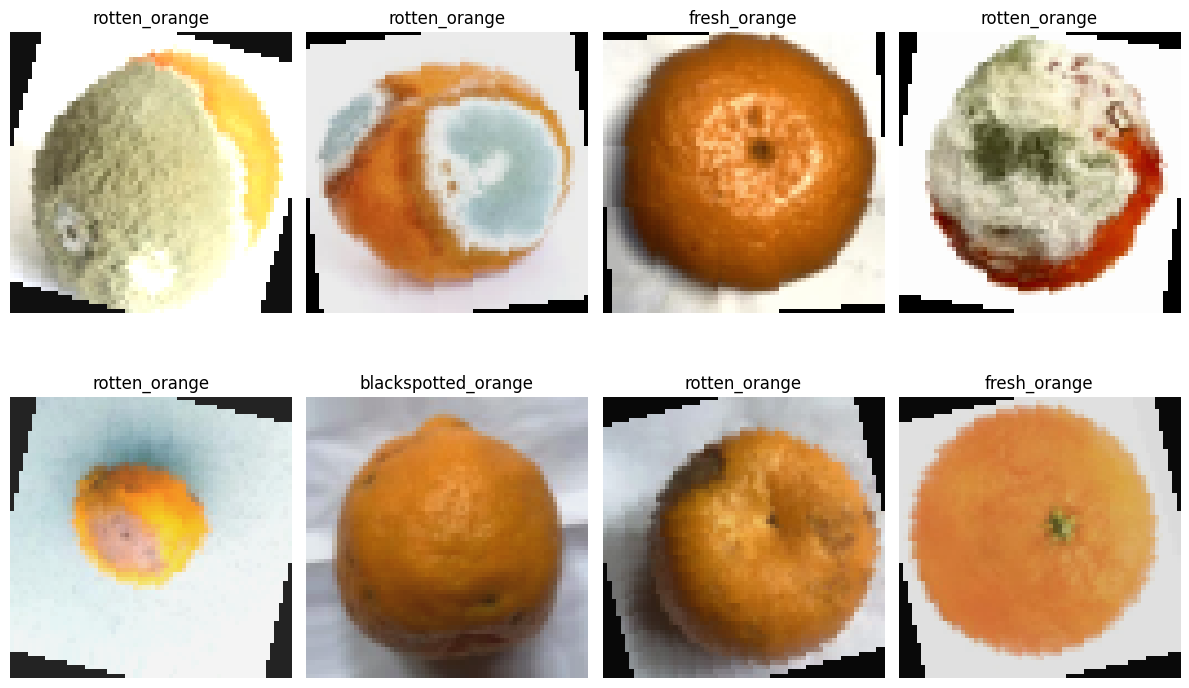

In [37]:
#visualize image
plt.figure(figsize=(12, 8))

for i in range(8):
    image, label = train_dataset[i]

    plt.subplot(2, 4, i + 1)

    plt.imshow(image.permute(1, 2, 0))
    plt.title(train_data.classes[label])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [45]:
#hyperparameters
batch_size = 16
learning_rate = 0.001

minimum_learning_rate = 1e-4

epochs = 30

num_classes = 5

In [46]:
#data loader
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [47]:
#implement cnn
from torch.optim import Adam
from torch.optim.lr_scheduler import CosineAnnealingLR

class CNNModel(nn.Module):

    def __init__(self, num_classes=5 , img_size = 64):

        super(CNNModel, self).__init__()

        # Convolutional layers
        self.conv_layers = nn.Sequential(

            nn.Conv2d(3, 64, kernel_size=3 , padding = 1),
            nn.MaxPool2d(2),
            nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=3 , padding = 1),
            nn.MaxPool2d(2),
            nn.ReLU(),

            nn.Conv2d(128, 128, kernel_size=3 , padding = 1),
            nn.MaxPool2d(2),
            nn.ReLU()
        )

        with torch.no_grad():
          dummy = torch.zeros(1,3, img_size , img_size)
          flattened_features = self.conv_layers(dummy).numel()

        # Fully connected layers
        self.fc_layers = nn.Sequential(

            nn.Flatten(),

            nn.Linear(flattened_features, 256),

            nn.ReLU(),

            nn.Dropout(0.5),

            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        x = self.conv_layers(x)

        x = self.fc_layers(x)

        return x

In [48]:
#initialize the model optimizer scheduler and loss
model = CNNModel(num_classes=5).to(device)

optimizer = Adam(
    model.parameters(),
    lr=learning_rate
)

scheduler = CosineAnnealingLR(
    optimizer,
    T_max=epochs,
    eta_min=minimum_learning_rate
)

criterion = nn.CrossEntropyLoss()

In [49]:
print(model)

CNNModel(
  (conv_layers): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (2): ReLU()
    (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): ReLU()
    (6): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): ReLU()
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=5, bias=True)
  )
)


In [50]:
sample_images, sample_labels = next(iter(train_loader))

sample_images = sample_images.to(device)

outputs = model(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([16, 3, 64, 64])
Output shape: torch.Size([16, 5])


In [51]:
# training function
def train_epoch(model, loader, optimizer, criterion, device):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        # Calculate accuracy
        _, preds = torch.max(outputs, 1)

        correct += (preds == labels).sum().item()

        total += labels.size(0)

    train_loss = total_loss / len(loader)

    train_acc = correct / total

    return train_loss, train_acc

In [52]:
# validation function
def validate_epoch(model, loader, criterion, device):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            total_loss += loss.item()

            _, preds = torch.max(outputs, 1)

            correct += (preds == labels).sum().item()

            total += labels.size(0)

    val_loss = total_loss / len(loader)

    val_acc = correct / total

    return val_loss, val_acc

In [53]:
# train model
train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

for epoch in range(epochs):

    print("-" * 60)

    print(
        f"Epoch {epoch + 1}/{epochs}, "
        f"LR: {optimizer.param_groups[0]['lr']:.6f}"
    )

    train_loss, train_acc = train_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        device
    )

    val_loss, val_acc = validate_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    scheduler.step()

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")

    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

------------------------------------------------------------
Epoch 1/30, LR: 0.001000
Train Loss: 0.6569 | Train Acc: 0.7443
Val Loss: 0.4457 | Val Acc: 0.8271
------------------------------------------------------------
Epoch 2/30, LR: 0.000998
Train Loss: 0.3900 | Train Acc: 0.8553
Val Loss: 0.2384 | Val Acc: 0.9151
------------------------------------------------------------
Epoch 3/30, LR: 0.000990
Train Loss: 0.2855 | Train Acc: 0.8952
Val Loss: 0.1627 | Val Acc: 0.9404
------------------------------------------------------------
Epoch 4/30, LR: 0.000978
Train Loss: 0.2222 | Train Acc: 0.9192
Val Loss: 0.1479 | Val Acc: 0.9462
------------------------------------------------------------
Epoch 5/30, LR: 0.000961
Train Loss: 0.1834 | Train Acc: 0.9353
Val Loss: 0.0805 | Val Acc: 0.9662
------------------------------------------------------------
Epoch 6/30, LR: 0.000940
Train Loss: 0.1560 | Train Acc: 0.9436
Val Loss: 0.0743 | Val Acc: 0.9676
----------------------------------------

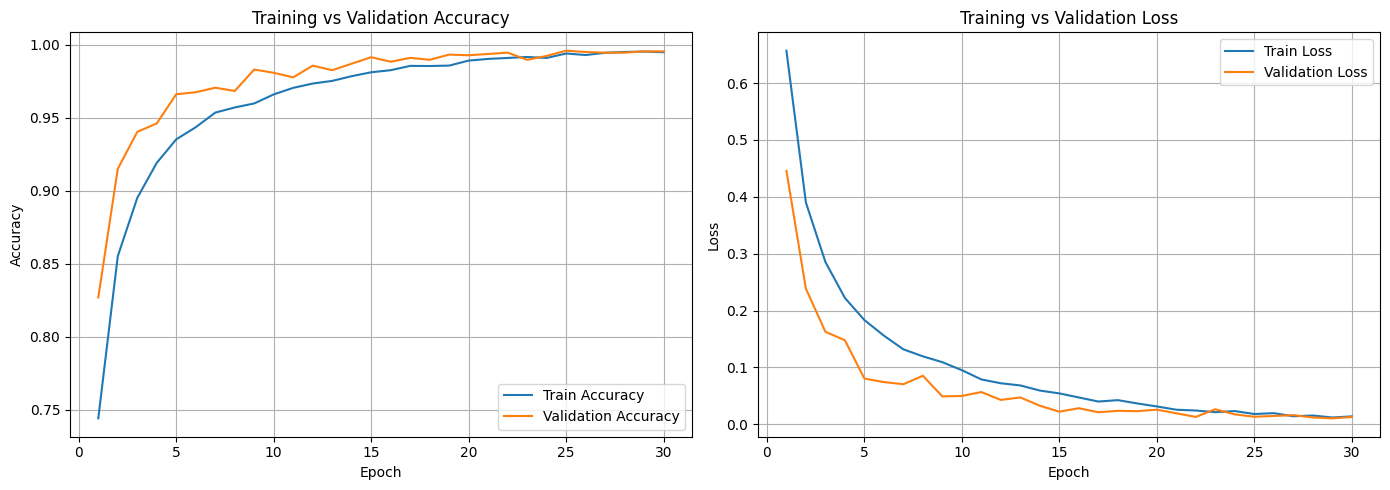

In [54]:
epochs_number = range(1, epochs + 1)

plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(epochs_number, train_accuracies, label='Train Accuracy')
plt.plot(epochs_number, val_accuracies, label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')

plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)

plt.plot(epochs_number, train_losses, label='Train Loss')
plt.plot(epochs_number, val_losses, label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [55]:
test_loss, test_acc = validate_epoch(
    model,
    test_loader,
    criterion,
    device
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")

Test Loss: 0.0097
Test Accuracy: 0.9960
Test Accuracy: 99.60%


In [56]:
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())

        all_labels.extend(labels.numpy())

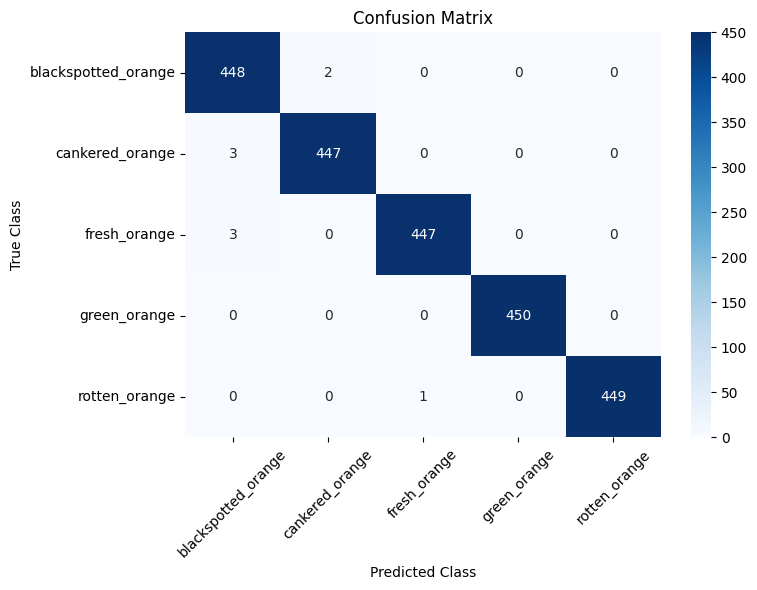

In [57]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=full_dataset.classes,
    yticklabels=full_dataset.classes
)

plt.xlabel('Predicted Class')
plt.ylabel('True Class')

plt.title('Confusion Matrix')

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()

plt.show()

In [58]:
print(
    classification_report(
        all_labels,
        all_preds,
        target_names=full_dataset.classes
    )
)

                     precision    recall  f1-score   support

blackspotted_orange       0.99      1.00      0.99       450
    cankered_orange       1.00      0.99      0.99       450
       fresh_orange       1.00      0.99      1.00       450
       green_orange       1.00      1.00      1.00       450
      rotten_orange       1.00      1.00      1.00       450

           accuracy                           1.00      2250
          macro avg       1.00      1.00      1.00      2250
       weighted avg       1.00      1.00      1.00      2250



In [59]:
torch.save(
    model.state_dict(),
    '/content/orange_cnn_model.pth'
)

print("Model saved successfully!")

Model saved successfully!
